# 04 · EMT-TF Expression (unconditional)

Categorical overlay of thresholded EMT-TF expressers on a grey manifold. A **wide** panel (Snail/Zeb/Twist + FOXC/PRRX mesenchymal families); VIM is excluded (a mesenchymal marker, not a TF). Gate on detectable expression; classify each factor by its pseudotime end.

In [1]:
import os, sys, glob, io, contextlib, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.stats import spearmanr
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging
for _h in ['harmonypy']:
    logging.getLogger(_h).setLevel(logging.ERROR); logging.getLogger(_h).propagate=False; logging.getLogger(_h).disabled=True

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load signatures (has pseudotime + house layout)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 1082 | pseudotime 0.0 -> 11.52


### Score the EMT-TF panel; gate on detection; classify by pseudotime end

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x = X[:,j]; expr = x>0; rho,_ = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(origin)', 'LATE(terminus)')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
body_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
terminus_tf = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nexpressed EMT-TFs (frac>3%): {len(ok)} ({list(ok.TF)})')
print(f'origin/body factor (min rho) = {body_tf}; terminus factor (max rho) = {terminus_tf}')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.048       0.026      0.005    -0.101  EARLY(origin)
TWIST1      0.032       0.009      0.002    -0.074  EARLY(origin)
 PRRX2      0.031       0.006      0.007    -0.033 LATE(terminus)
  ZEB1      0.033       0.011      0.003    -0.031  EARLY(origin)
  ZEB2      0.430       0.131      0.123    -0.007  EARLY(origin)
 SNAI2      0.274       0.073      0.084     0.017 LATE(terminus)
 SNAI1      0.006       0.000      0.001     0.034 LATE(terminus)
 PRRX1      0.155       0.040      0.045     0.060 LATE(terminus)

expressed EMT-TFs (frac>3%): 7 (['FOXC1', 'TWIST1', 'PRRX2', 'ZEB1', 'ZEB2', 'SNAI2', 'PRRX1'])
origin/body factor (min rho) = FOXC1; terminus factor (max rho) = PRRX1


### Categorical overlay on grey manifold (reference style)

overlay thresholds (upper quartile among expressers): {'FOXC1': 0.35, 'PRRX1': 0.48} | cells shown: {'FOXC1': 13, 'PRRX1': 42}
FOXC1: 4.8% expressing; 13 shown; mean pseudotime of shown = 0.27
PRRX1: 15.5% expressing; 42 shown; mean pseudotime of shown = 0.53
saved expression.pdf


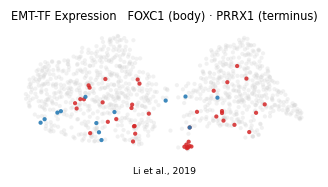

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr={}
for g in [body_tf, terminus_tf]:
    v = vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: vec(g) > thr[g] for g in [body_tf, terminus_tf]}
print('overlay thresholds (upper quartile among expressers):', {g:round(thr[g],2) for g in thr},
      '| cells shown:', {g:int(sel[g].sum()) for g in sel})
order = sorted([body_tf, terminus_tf], key=lambda g: -int(sel[g].sum()))
colors = {body_tf:'tab:blue', terminus_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {body_tf} (body) \u00b7 {terminus_tf} (terminus)', size=7.5)
ax.text(.5,-.14,'Li et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [body_tf, terminus_tf]:
    m = sel[g]
    print(f'{g}: {(vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown; mean pseudotime of shown = {tn[m].mean():.2f}')
print('saved expression.pdf')